In [1]:
import pandas as pd
import json

In [2]:
def load_and_format_jump_data(filepath, column_mapping):
    """
    Load a CSV file and format it with column mapping and uncertainty columns.
    Location name is automatically extracted from filename.
    
    Parameters:
    -----------
    filepath : str
        Path to the CSV file (e.g., "data/clinic.csv")
    column_mapping : dict
        Dictionary mapping old column names to new names
    
    Returns:
    --------
    pd.DataFrame
        Formatted dataframe with renamed columns, uncertainty columns, and location column
    """
    # Extract location name from filename (e.g., "data/clinic.csv" -> "clinic")
    location_name = os.path.splitext(os.path.basename(filepath))[0]
    
    # Read the CSV, skipping the first row if it contains summary data
    df = pd.read_csv(filepath, skiprows=1)
    
    # Get all column names from the original dataframe
    all_columns = df.columns.tolist()
    
    # Build list of columns to keep (mapped columns + their uncertainty columns)
    columns_to_keep = []
    rename_dict = {}
    
    for old_name in column_mapping.keys():
        if old_name in all_columns:
            # Add the main column
            columns_to_keep.append(old_name)
            rename_dict[old_name] = column_mapping[old_name]
            
            # Check if next column is an uncertainty column
            col_idx = all_columns.index(old_name)
            if col_idx + 1 < len(all_columns):
                next_col = all_columns[col_idx + 1]
                # Check if it matches pattern "unc" or "unc.i" where i is any integer
                if next_col.strip().lower().startswith('unc'):
                    columns_to_keep.append(next_col)
                    # Rename uncertainty column to match its paired column
                    new_base_name = column_mapping[old_name]
                    rename_dict[next_col] = f"{new_base_name}_unc"
    
    # Select only the columns we want and rename them
    df = df[columns_to_keep].rename(columns=rename_dict)
    
    # Add location column
    df.insert(0, 'spot', location_name)
    
    return df

In [3]:
# Load all CSV files and combine into one global dataframe
import glob
import os

# Load column mapping
with open('column_mappings.json', 'r') as f:
    all_mappings = json.load(f)
column_mapping = all_mappings['all']

# Get all CSV files in the data directory
csv_files = glob.glob("data/*.csv")

# List to store individual dataframes
dfs = []

# Loop through each CSV file
for filepath in csv_files:
    try:
        df = load_and_format_jump_data(filepath, column_mapping)
        location = df['spot'].iloc[0]  # Get location name from the dataframe
        dfs.append(df)
        print(f"✓ Loaded {location}: {len(df)} jumps")
    except Exception as e:
        print(f"✗ Error loading {filepath}: {e}")

# Combine all dataframes into one
df_all = pd.concat(dfs, ignore_index=True)

print(f"\n{'='*60}")
print(f"GLOBAL DATAFRAME CREATED")
print(f"{'='*60}")
print(f"Total jumps: {len(df_all)}")
print(f"Locations: {df_all['spot'].unique().tolist()}")
print(f"\nColumns: {df_all.columns.tolist()}")
# print(f"\nJumps per location:")
# print(df_all['location'].value_counts())
# print(f"\nFirst few rows:")
# print(df_all.head(10))

✓ Loaded loutet: 4 jumps
✓ Loaded nettle: 8 jumps
✓ Loaded laguna: 3 jumps
✓ Loaded jc: 5 jumps
✓ Loaded bridge: 8 jumps
✓ Loaded fp: 8 jumps
✓ Loaded riverside: 6 jumps
✓ Loaded clinic: 6 jumps

GLOBAL DATAFRAME CREATED
Total jumps: 48
Locations: ['loutet', 'nettle', 'laguna', 'jc', 'bridge', 'fp', 'riverside', 'clinic']

Columns: ['spot', 'type', 'jump', 'gap_cm', 'gap_cm_unc', 'dll_m', 'spacing_info', 'spacing_info_unc', 'height_cm', 'height_cm_unc', 'landing_height_cm', 'landing_height_cm_unc', 'theta_phone', 'theta_stick']


In [4]:
## Define qualitative columns to keep as strings
qualitativeColumns = ['spot', 'type', 'jump', 'spacing_info']

# Numeric columns = everything except qualitative columns and uncertainty columns
numericColumns = [col for col in df_all.columns if col not in qualitativeColumns and 'unc' not in col]

## remove unc columns (for now, quick testing)
uncColumns = [col for col in df_all.columns if 'unc' in col]
df_all.drop(columns=uncColumns, inplace=True)

# Keep all columns in the dataframe
dfNum = df_all.copy()

print(f"\n{'='*60}")
print(f"DATAFRAME INFO")
print(f"{'='*60}")
print(f"Total jumps: {len(dfNum)}")
print(f"\nQualitative columns (kept as strings): {qualitativeColumns}")
print(f"\nNumeric columns to convert: {numericColumns}")

## convert all 'x' or '-' entries to NaN
dfNum.replace(['x', '-'], pd.NA, inplace=True)

dfNum.head(100)


DATAFRAME INFO
Total jumps: 48

Qualitative columns (kept as strings): ['spot', 'type', 'jump', 'spacing_info']

Numeric columns to convert: ['gap_cm', 'dll_m', 'height_cm', 'landing_height_cm', 'theta_phone', 'theta_stick']


,spot,type,jump,gap_cm,dll_m,spacing_info,height_cm,landing_height_cm,theta_phone,theta_stick
0,loutet,straight,burger,365,<NA>,first jump,179.705,<NA>,63.0,57
1,loutet,straight,second,360,1105,normal,165.1,<NA>,60.0,54
2,loutet,straight,third (to be removed),375,1150,normal,166.37,<NA>,57.5,52
3,loutet,hip right,hip,400,1160,normal,162.56,<NA>,61.0,52
4,nettle,roller,roller,<NA>,<NA>,berm,<NA>,<NA>,90.0,90
5,nettle,straight,straight,365,970,berm,213.36,270.51,62.5,58
6,nettle,hip left,hip,350,1195,normal,215.9,260.35,65.0,60
7,nettle,straight,trick,375,1280,normal,203.2,228.6,63.0,56
8,nettle,hip right,right hip,440,1320,normal,212.725,245.745,62.0,58
9,nettle,hip left,long left hip,490,1395,normal,213.36,243.84,66.0,60


In [5]:
import numpy as np

# Convert all numeric columns to numeric type (coerce non-numeric values to NaN)
for col in numericColumns:
    if col in dfNum.columns:
        dfNum[col] = pd.to_numeric(dfNum[col], errors='coerce')

print(f"Converted {len(numericColumns)} columns to numeric type")

# Now calculations will safely handle NaN values
deg2rad = np.pi / 180.0

## doing math ##
dfNum['R_eff_phone_m'] = dfNum['height_cm'] / (1 - np.cos(deg2rad * dfNum['theta_phone']))/100
dfNum['R_eff_stick_m'] = dfNum['height_cm'] / (1 - np.cos(deg2rad * dfNum['theta_stick']))/100

# airtime1
dfNum["at1_degxm"] = dfNum["theta_phone"] * dfNum["gap_cm"]/100
dfNum["at2_degxm"] = dfNum["theta_stick"] * dfNum["gap_cm"]/100

dfNum["area_mxm"] = dfNum["gap_cm"] * dfNum["height_cm"] / 100 / 100

newNumericColumns = ["R_eff_phone_m", "R_eff_stick_m", "at1_degxm", "at2_degxm", "area_mxm"]

# Check results
print(f"Rows with valid R_eff_phone: {dfNum['R_eff_phone_m'].notna().sum()} / {len(dfNum)}")

dfNum.head(5)

Converted 6 columns to numeric type
Rows with valid R_eff_phone: 41 / 48


,spot,type,jump,gap_cm,dll_m,spacing_info,height_cm,landing_height_cm,theta_phone,theta_stick,R_eff_phone_m,R_eff_stick_m,at1_degxm,at2_degxm,area_mxm
0,loutet,straight,burger,365.0,NaN,first jump,179.705,NaN,63.0,57.0,3.291243,3.946430,229.950,208.05,6.559233
1,loutet,straight,second,360.0,1105.0,normal,165.100,NaN,60.0,54.0,3.302000,4.005194,216.000,194.40,5.943600
2,loutet,straight,third (to be removed),375.0,1150.0,normal,166.370,NaN,57.5,52.0,3.595631,4.328736,215.625,195.00,6.238875
3,loutet,hip right,hip,400.0,1160.0,normal,162.560,NaN,61.0,52.0,3.155338,4.229605,244.000,208.00,6.502400
4,nettle,roller,roller,NaN,NaN,berm,NaN,NaN,90.0,90.0,NaN,NaN,NaN,NaN,NaN


---
### Filtering

In [6]:
## after-the-fact filtering

# Remove rows where spot='jc' AND height_cm < 100
dfNum = dfNum[~((dfNum['spot'] == 'jc') & (dfNum['height_cm'] < 100))]

Available numeric columns for plotting:
 1. gap_cm
 2. dll_m
 3. height_cm
 4. landing_height_cm
 5. theta_phone
 6. theta_stick
 7. R_eff_phone_m
 8. R_eff_stick_m
 9. at1_degxm
10. at2_degxm
11. area_mxm


Plotting data for 8 spots:
  loutet: [0.12156863 0.46666667 0.70588235] / o
  nettle: [1.         0.49803922 0.05490196] / s
  laguna: [0.17254902 0.62745098 0.17254902] / ^
  jc: [0.83921569 0.15294118 0.15686275] / D
  bridge: [0.58039216 0.40392157 0.74117647] / v
  fp: [0.54901961 0.3372549  0.29411765] / <
  riverside: [0.89019608 0.46666667 0.76078431] / >
  clinic: [0.49803922 0.49803922 0.49803922] / p




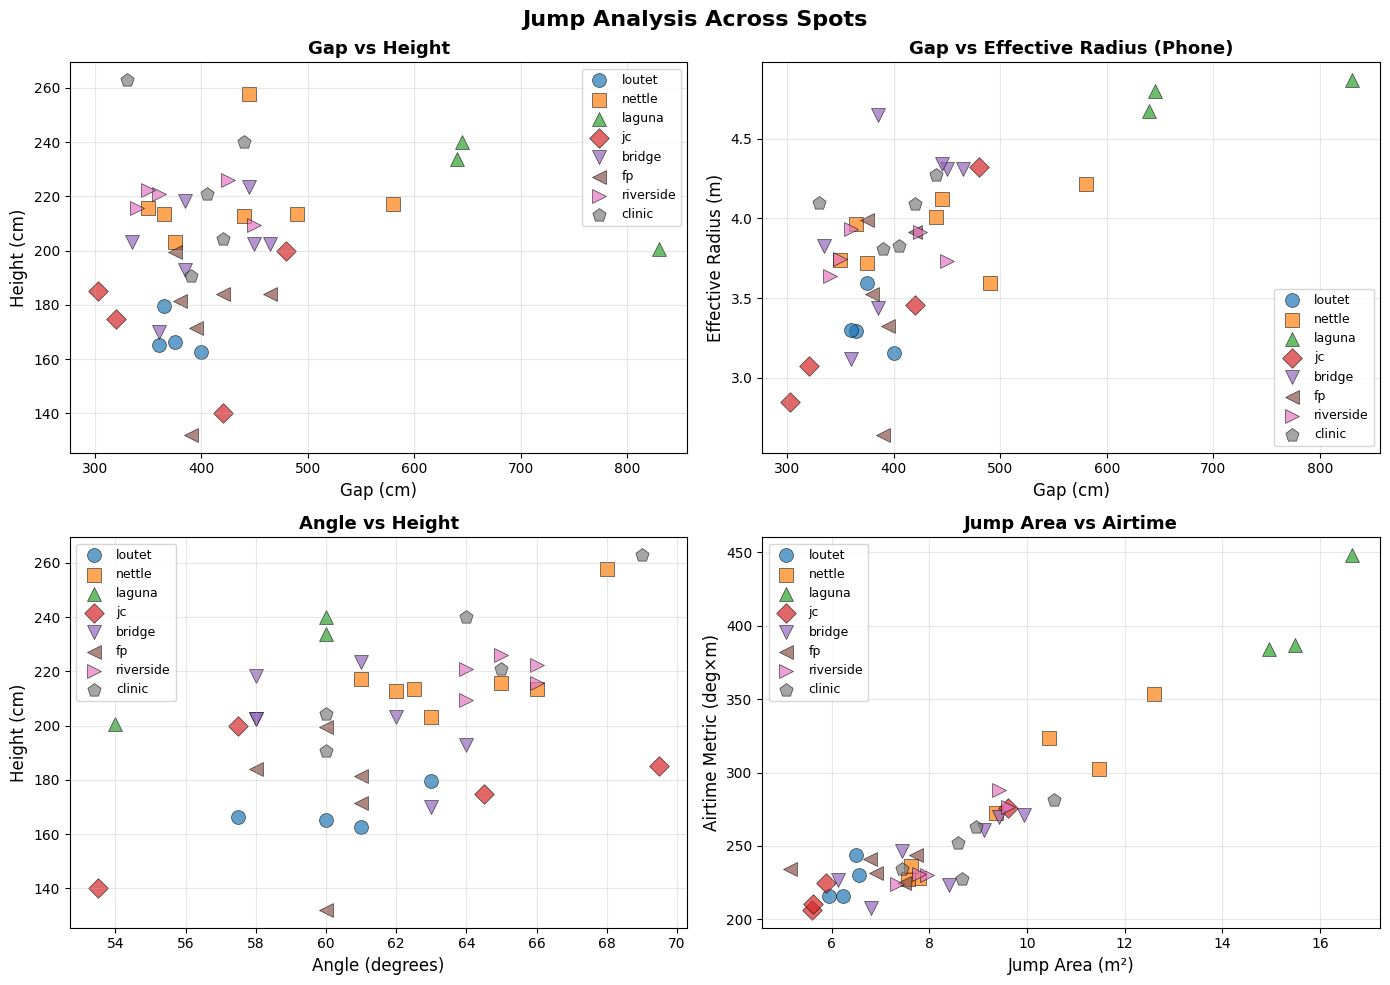

In [9]:
import matplotlib.pyplot as plt

# Print available numeric columns for plotting
print("Available numeric columns for plotting:")
print("=" * 60)
for i, col in enumerate(numericColumns + newNumericColumns, 1):
    print(f"{i:2d}. {col}")
print("\n")

# Get unique spots and assign colors/markers
spots = dfNum['spot'].unique()
colors = plt.cm.tab10(range(len(spots)))  # Use tab10 colormap
markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p']  # Different marker styles

print(f"Plotting data for {len(spots)} spots:")
for i, spot in enumerate(spots):
    print(f"  {spot}: {colors[i][:3]} / {markers[i % len(markers)]}")
print("\n")

# Create figure with multiple subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Jump Analysis Across Spots', fontsize=16, fontweight='bold')

# Plot 1: Gap vs Height
ax = axes[0, 0]
for i, spot in enumerate(spots):
    spot_data = dfNum[dfNum['spot'] == spot]
    ax.scatter(spot_data['gap_cm'], spot_data['height_cm'], 
               c=[colors[i]], marker=markers[i % len(markers)], 
               label=spot, s=100, alpha=0.7, edgecolors='black', linewidth=0.5)
ax.set_xlabel('Gap (cm)', fontsize=12)
ax.set_ylabel('Height (cm)', fontsize=12)
ax.set_title('Gap vs Height', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# Plot 2: Gap vs Effective Radius (phone)
ax = axes[0, 1]
for i, spot in enumerate(spots):
    spot_data = dfNum[dfNum['spot'] == spot]
    ax.scatter(spot_data['gap_cm'], spot_data['R_eff_phone_m'], 
               c=[colors[i]], marker=markers[i % len(markers)], 
               label=spot, s=100, alpha=0.7, edgecolors='black', linewidth=0.5)
ax.set_xlabel('Gap (cm)', fontsize=12)
ax.set_ylabel('Effective Radius (m)', fontsize=12)
ax.set_title('Gap vs Effective Radius (Phone)', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# Plot 3: Angle vs Height
ax = axes[1, 0]
for i, spot in enumerate(spots):
    spot_data = dfNum[dfNum['spot'] == spot]
    ax.scatter(spot_data['theta_phone'], spot_data['height_cm'], 
               c=[colors[i]], marker=markers[i % len(markers)], 
               label=spot, s=100, alpha=0.7, edgecolors='black', linewidth=0.5)
ax.set_xlabel('Angle (degrees)', fontsize=12)
ax.set_ylabel('Height (cm)', fontsize=12)
ax.set_title('Angle vs Height', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

# Plot 4: Jump Area vs Airtime Metric
ax = axes[1, 1]
for i, spot in enumerate(spots):
    spot_data = dfNum[dfNum['spot'] == spot]
    ax.scatter(spot_data['area_mxm'], spot_data['at1_degxm'], 
               c=[colors[i]], marker=markers[i % len(markers)], 
               label=spot, s=100, alpha=0.7, edgecolors='black', linewidth=0.5)
ax.set_xlabel('Jump Area (m²)', fontsize=12)
ax.set_ylabel('Airtime Metric (deg×m)', fontsize=12)
ax.set_title('Jump Area vs Airtime', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

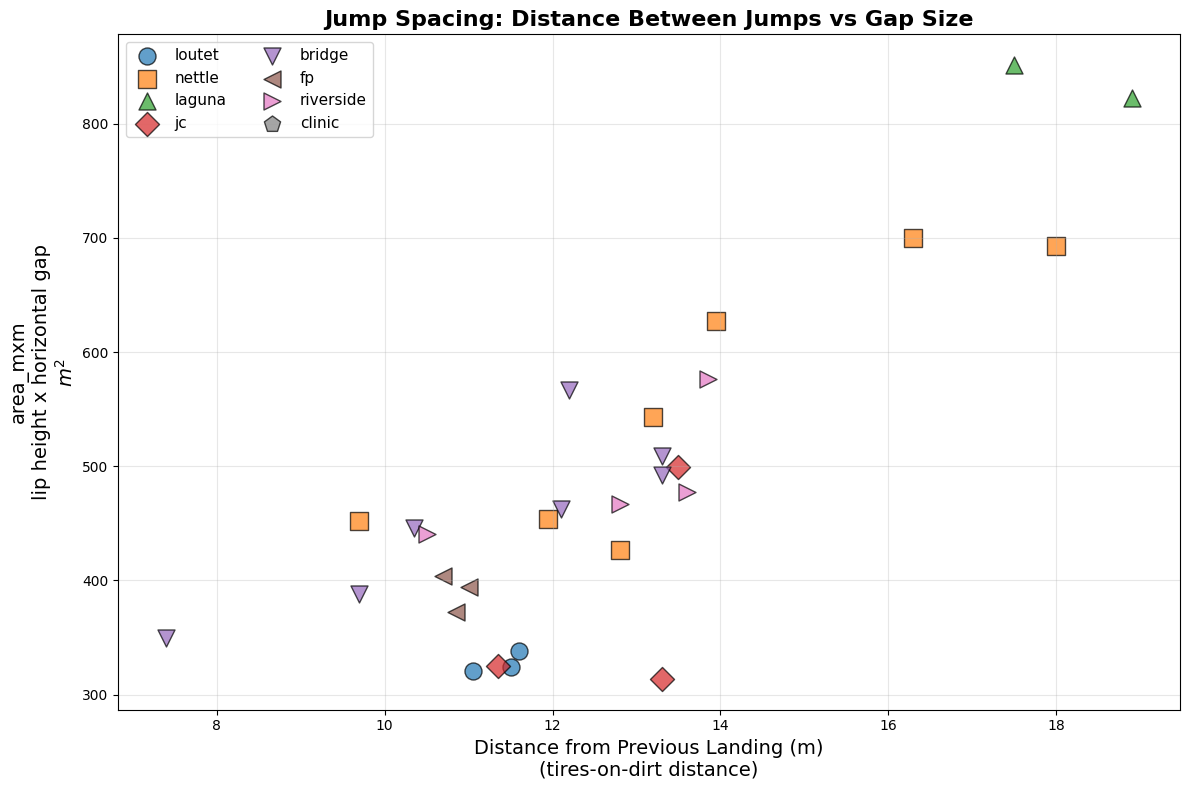


✅ Plots created! You can now:
   - Change x and y variables to any numeric columns
   - Adjust figure size with figsize=(width, height)
   - Modify marker sizes with s=value
   - Add more subplots or create single plots


In [ ]:
# Bonus: Single larger plot example - customize as needed!
fig, ax = plt.subplots(figsize=(12, 8))

xCol = 'dll_m'
yCol = 'area_mxm'
# Example: Distance between jumps vs Gap
for i, spot in enumerate(spots):
    spot_data = dfNum[dfNum['spot'] == spot]
    xDat = spot_data[xCol]/100
    yDat = spot_data[yCol] * spot_data["theta_stick"]
    ax.scatter(xDat, yDat, 
               c=[colors[i]], marker=markers[i % len(markers)], 
               label=spot, s=150, alpha=0.7, edgecolors='black', linewidth=1)

ax.set_xlabel('Distance from Previous Landing (m)\n(tires-on-dirt distance)', fontsize=14)
ax.set_ylabel(yCol+"\nlip height x horizontal gap\n"+ r"$m^2$", fontsize=14)
ax.set_title('Jump Spacing: Distance Between Jumps vs Size', fontsize=16, fontweight='bold')
ax.legend(loc='best', fontsize=11, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n✅ Plots created! You can now:")
print("   - Change x and y variables to any numeric columns")
print("   - Adjust figure size with figsize=(width, height)")
print("   - Modify marker sizes with s=value")
print("   - Add more subplots or create single plots")